# Ex2_homogeneous_one_group

A homogeneous one group slab with vacuum boundary conditions.


In [1]:
from pathlib import Path
import sys

try:
    import ipywidgets as widgets
except ModuleNotFoundError:
    # The Pyodide kernel does not inherit packages installed in the
    # environment that built the JupyterLite site.
    import piplite
    await piplite.install('ipywidgets==8.1.7')
    import ipywidgets as widgets

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

working_directory = Path.cwd().resolve()
candidates = (
    working_directory, *working_directory.parents,
    working_directory / 'Ex_RP_SN_discrete_ordinates',
    working_directory / 'RPTT_PoliTO_GitHub' / 'Ex_RP_SN_discrete_ordinates',
)
PROJECT_DIRECTORY = next(
    (path for path in candidates if (path / 'sn_1d.py').is_file()), None
)
if PROJECT_DIRECTORY is None:
    raise FileNotFoundError('Cannot find sn_1d.py.')

sys.path.insert(0, str(PROJECT_DIRECTORY))
from sn_1d import SNSettings, SNSolver, SlabMesh, SlabSNProblem

DATA_DIRECTORY = PROJECT_DIRECTORY / 'data'
plt.rcParams.update({'figure.figsize': (8, 4.5), 'axes.grid': True})
print(f'Input: {DATA_DIRECTORY}')


Input: /home/nabrate/RPTT_PoliTO_GitHub/Ex_RP_SN_discrete_ordinates/data


In [2]:
def _inner_counts_at_power(result, power_frame):
    # power_frame is deliberately zero based, as in an animation timeline.
    if not 0 <= power_frame < len(result.history):
        raise ValueError(
            f'power_frame must be between 0 and {len(result.history) - 1}.'
        )
    power = result.history[power_frame]
    outer_numbers = np.array(
        [outer.iteration for outer in power.outer_iterations], dtype=int
    )
    group_counts = np.array([
        [inner.iterations for inner in outer.inner_iterations]
        for outer in power.outer_iterations
    ], dtype=int)
    return power, outer_numbers, group_counts


def plot_inner_vs_outer(result, power_frame=0, show_groups=True, y_max=None):
    # Inner iterations versus outer iteration at one selected power frame.
    power, outer_numbers, group_counts = _inner_counts_at_power(
        result, power_frame
    )
    totals = group_counts.sum(axis=1)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(outer_numbers, totals, 'ko-', lw=2.2,
            label='Total over groups')
    if show_groups:
        for group, counts in enumerate(group_counts.T, start=1):
            ax.plot(outer_numbers, counts, 'o--', lw=1.2,
                    label=f'Group {group}')
    ax.set(
        xlabel='Outer iteration',
        ylabel='Number of inner iterations',
        title=(f'Power frame {power_frame} / {len(result.history) - 1} '
               f'(solver iteration {power.iteration}, '
               f'$k_{{eff}}={power.keff:.7f}$)'),
        xticks=outer_numbers,
    )
    ax.set_ylim(bottom=0, top=y_max)
    ax.legend()
    fig.tight_layout()
    return fig, ax


def inner_iteration_widget(result, initial_frame=0, interval=600,
                           repeat=True, show_groups=True, y_max=None):
    # Linked Play and slider controls animate all recorded power frames.
    last_frame = len(result.history) - 1
    if not 0 <= initial_frame <= last_frame:
        raise ValueError(f'initial_frame must be between 0 and {last_frame}.')
    global_y_max = 1.05 * max(
        sum(inner.iterations for inner in outer.inner_iterations)
        for power in result.history
        for outer in power.outer_iterations
    )

    play = widgets.Play(
        value=initial_frame, min=0, max=last_frame, step=1,
        interval=interval, description='Play', repeat=repeat,
    )
    frame = widgets.IntSlider(
        value=initial_frame, min=0, max=last_frame, step=1,
        description='Power frame', continuous_update=False,
        readout=True, layout=widgets.Layout(width='520px'),
    )
    speed = widgets.IntSlider(
        value=interval, min=100, max=2000, step=100,
        description='Frame [ms]', continuous_update=False,
        layout=widgets.Layout(width='360px'),
    )
    repeat_control = widgets.Checkbox(value=repeat, description='Repeat')
    groups_control = widgets.Checkbox(
        value=show_groups, description='Show single groups'
    )
    y_limit = widgets.FloatText(
        value=0.0 if y_max is None else y_max,
        description='Y max (0=global)',
        layout=widgets.Layout(width='220px'),
    )

    widgets.jslink((play, 'value'), (frame, 'value'))
    widgets.jslink((speed, 'value'), (play, 'interval'))
    widgets.jslink((repeat_control, 'value'), (play, 'repeat'))

    def redraw(power_frame, show_single_groups, requested_y_max):
        upper_limit = (global_y_max if requested_y_max <= 0
                       else requested_y_max)
        plot_inner_vs_outer(
            result, power_frame=power_frame,
            show_groups=show_single_groups, y_max=upper_limit,
        )
        plt.show()

    output = widgets.interactive_output(
        redraw,
        {
            'power_frame': frame,
            'show_single_groups': groups_control,
            'requested_y_max': y_limit,
        },
    )
    controls = widgets.VBox([
        widgets.HBox([play, frame]),
        widgets.HBox([speed, repeat_control, groups_control, y_limit]),
    ])
    return widgets.VBox([controls, output])


def plot_power_convergence(result):
    # Compare the two stopping indicators of the power method.
    power_numbers = np.array([step.iteration for step in result.history])
    keff_errors = np.array([step.keff_error for step in result.history])
    flux_l2_errors = np.array([step.flux_l2_error for step in result.history])

    fig, (ax_keff, ax_flux) = plt.subplots(
        2, 1, sharex=True, figsize=(8, 6)
    )
    ax_keff.semilogy(power_numbers, keff_errors, 'o-', ms=3,
                      label=r'Relative $k_{eff}$ error')
    ax_keff.axhline(result.settings.eigenvalue_tolerance, color='tab:red',
                    ls='--', label='Eigenvalue tolerance')
    ax_keff.set(ylabel='Relative error', title='Power-method convergence')
    ax_keff.legend()

    ax_flux.semilogy(power_numbers, flux_l2_errors, 'o-', ms=3,
                     label=r'Relative scalar-flux $L_2$ change')
    ax_flux.axhline(result.settings.power_flux_tolerance, color='tab:red',
                    ls='--', label='Scalar-flux tolerance')
    ax_flux.set(xlabel='Power iteration', ylabel='Relative $L_2$ change')
    ax_flux.legend()
    fig.tight_layout()
    return fig, (ax_keff, ax_flux)


def plot_angular_and_scalar_flux(result, group=0, direction='all',
                                 normalize=True):
    # Select one group and either scalar, all angular, or one direction.
    if not 0 <= group < result.scalar_flux.shape[0]:
        raise ValueError('GROUP_TO_PLOT is out of range.')
    x = result.problem.mesh.cell_centers
    angular = result.angular_flux[group].copy()
    scalar = result.scalar_flux[group].copy()
    if normalize:
        scale = np.max(np.abs(scalar))
        angular /= scale
        scalar /= scale
        ylabel = 'flux / maximum scalar flux of the group'
    else:
        ylabel = 'flux'
    signed_mu = np.r_[result.directions, -result.directions]
    fig, ax = plt.subplots()
    if direction == 'all':
        for ordinate, mu in enumerate(signed_mu):
            ax.plot(x, angular[ordinate], lw=1, alpha=0.75,
                    label=fr'$\psi(\mu={mu:+.3f})$')
    elif direction != 'scalar':
        if not isinstance(direction, (int, np.integer)):
            raise ValueError("direction must be 'all', 'scalar', or an index.")
        if not 0 <= direction < len(signed_mu):
            raise ValueError('The direction index is out of range.')
        mu = signed_mu[direction]
        ax.plot(x, angular[direction], lw=2,
                label=fr'$\psi(\mu={mu:+.3f})$')
    ax.plot(x, scalar, 'k', lw=2.8,
            ls='--' if direction not in ('all', 'scalar') else '-',
            label=fr'$\phi_{{{group + 1}}}$')
    for interface in result.problem.mesh.region_edges[1:-1]:
        ax.axvline(interface, color='0.6', ls='--', lw=0.8)
    ax.set(xlabel='$z$ [cm]', ylabel=ylabel,
           title=f'Flux — group {group + 1}')
    ax.legend(ncol=2, fontsize=8)
    fig.tight_layout()
    return fig, ax


def flux_widget(result, initial_group=0, initial_direction='all',
                normalize=True):
    # Interactive group/direction selection without rerunning the solver.
    groups = result.scalar_flux.shape[0]
    signed_mu = np.r_[result.directions, -result.directions]
    direction_options = [('All angular directions', 'all'),
                         ('Scalar flux only', 'scalar')]
    direction_options.extend(
        (f'Direction {index}: mu={mu:+.5f}', index)
        for index, mu in enumerate(signed_mu)
    )
    valid_directions = {value for _, value in direction_options}
    if not 0 <= initial_group < groups:
        raise ValueError(f'initial_group must be between 0 and {groups - 1}.')
    if initial_direction not in valid_directions:
        raise ValueError('initial_direction is not available.')

    group_control = widgets.Dropdown(
        options=[(f'Group {group + 1}', group) for group in range(groups)],
        value=initial_group, description='Energy group',
    )
    direction_control = widgets.Dropdown(
        options=direction_options, value=initial_direction,
        description='Direction',
        layout=widgets.Layout(width='310px'),
    )
    normalize_control = widgets.Checkbox(
        value=normalize, description='Normalize by max scalar flux'
    )

    def redraw(group, direction, normalize_flux):
        plot_angular_and_scalar_flux(
            result, group=group, direction=direction,
            normalize=normalize_flux,
        )
        plt.show()

    output = widgets.interactive_output(
        redraw,
        {
            'group': group_control,
            'direction': direction_control,
            'normalize_flux': normalize_control,
        },
    )
    controls = widgets.HBox(
        [group_control, direction_control, normalize_control]
    )
    return widgets.VBox([controls, output])


def remesh_problem(problem, target_width):
    # Preserve geometry and materials while changing the spatial mesh.
    lengths = np.diff(problem.mesh.region_edges)
    cells = np.maximum(1, np.rint(lengths / target_width).astype(int))
    mesh = SlabMesh(problem.mesh.region_edges.copy(), cells)
    return SlabSNProblem(mesh, problem.cross_sections,
                         name=f'{problem.name}, dz~{target_width:g} cm')


def keff_parameter_study(base_problem, orders, target_widths,
                         use_previous_flux=True):
    values = np.empty((len(target_widths), len(orders)))
    cell_counts = np.empty(len(target_widths), dtype=int)
    for row, width in enumerate(target_widths):
        problem = remesh_problem(base_problem, width)
        cell_counts[row] = problem.mesh.number_of_cells
        for col, order in enumerate(orders):
            settings = SNSettings(
                order=order, inner_tolerance=1e-4, outer_tolerance=5e-4,
                eigenvalue_tolerance=1e-4,
                power_flux_tolerance=1e-4,
                multigroup_warm_start=use_previous_flux,
            )
            values[row, col] = SNSolver(problem, settings).solve_critical().keff
    return values, cell_counts


## Initial guess for inner iterations

Set `USE_PREVIOUS_FLUX_AS_INNER_GUESS` to `True` to reuse the current
angular flux. On the first outer iteration of a power step, this is the
angular flux from the preceding power step. Set it to `False` to restart
every group solve from unit angular flux. In the fixed source problem,
the same switch controls reuse between outer iterations.


In [3]:
USE_PREVIOUS_FLUX_AS_INNER_GUESS = True
POWER_FLUX_TOLERANCE = 1.0e-7  # Relative scalar-flux L2 tolerance

settings = SNSettings(
    order=4, inner_tolerance=1e-06,
    outer_tolerance=0.0001, eigenvalue_tolerance=1e-06,
    power_flux_tolerance=POWER_FLUX_TOLERANCE,
    multigroup_warm_start=USE_PREVIOUS_FLUX_AS_INNER_GUESS,
)
solver = SNSolver.from_case(
    DATA_DIRECTORY, case='homogeneous', multigroup=False, settings=settings
)

result = solver.solve_critical()

print(f'k_eff = {result.keff:.8f}')
print(f'power iterations = {result.power_iterations}')
print(f'groups = {result.scalar_flux.shape[0]}')
print(f'angular order = S_{result.settings.order}')
print(f'spatial regions = {result.problem.mesh.number_of_regions}')
print(f'spatial cells = {result.problem.mesh.number_of_cells}')
print(f'materials = {result.problem.cross_sections.region_materials}')


k_eff = 1.21499123
power iterations = 353
groups = 1
angular order = S_4
spatial regions = 1
spatial cells = 100
materials = ('fuel',)


## Inner versus outer iterations at one power step

`POWER_FRAME` is the zero-based position in the recorded power-method
history: frame 0 is the first completed power iteration and the last
frame is `result.power_iterations - 1`. The black curve is the total
number of inner iterations across all groups; the dashed curves show
the individual group contributions. Change the parameters below and
rerun only this cell to inspect one frame precisely.


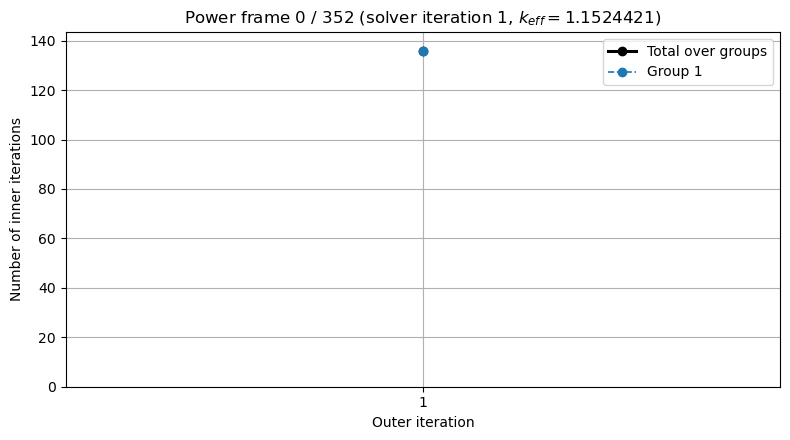

In [4]:
POWER_FRAME = 0
SHOW_GROUP_COUNTS = True
INNER_Y_MAX = None  # Use None for automatic scaling

plot_inner_vs_outer(
    result,
    power_frame=POWER_FRAME,
    show_groups=SHOW_GROUP_COUNTS,
    y_max=INNER_Y_MAX,
);


## Power-method convergence

The power method stops only when both curves are below their dashed
tolerance lines: the relative $k_{eff}$ error and the relative $L_2$
change of the scalar flux between two successive power iterations.


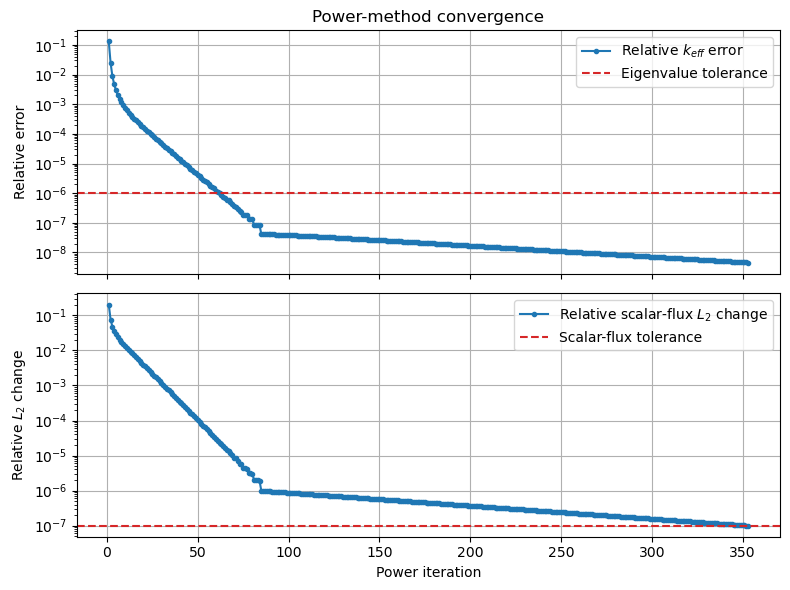

In [5]:
plot_power_convergence(result);


## Continuous animation of the nested iterations

Press play to move continuously from power frame 0 to the final
recorded frame, or drag the slider to any frame. The speed, repeat
mode, group curves, and vertical scale can also be changed directly
in the controls. `ANIMATION_INTERVAL_MS` is the initial delay between
frames.


In [6]:
ANIMATION_INTERVAL_MS = 600
ANIMATION_REPEAT = True

iteration_explorer = inner_iteration_widget(
    result,
    initial_frame=POWER_FRAME,
    interval=ANIMATION_INTERVAL_MS,
    repeat=ANIMATION_REPEAT,
    show_groups=SHOW_GROUP_COUNTS,
    y_max=INNER_Y_MAX,
)
display(iteration_explorer)


## Interactive angular and scalar flux

Select the energy group and one ordinate direction from the menus.
`All angular directions` overlays every angular flux, while
`Scalar flux only` hides them. With normalization enabled, angular and
scalar fluxes are divided by the maximum scalar flux of the selected
group, preserving their relative magnitudes.


In [7]:
INITIAL_GROUP = 0  # Zero-based Python group index
INITIAL_DIRECTION = 'all'  # 'all', 'scalar', or a direction index
NORMALIZE_FLUX = True

flux_explorer = flux_widget(
    result,
    initial_group=INITIAL_GROUP,
    initial_direction=INITIAL_DIRECTION,
    normalize=NORMALIZE_FLUX,
)
display(flux_explorer)


## Angular and spatial convergence of $k_{eff}$

Both panels report $(k-k_{\mathrm{finest}})\times10^5$ pcm, where
$k_{\mathrm{finest}}$ is computed at the largest angular order and
smallest target mesh width in the table below. Left: change $N$ for
each fixed mesh. Right: change the spatial mesh for each fixed $N$.
The number of energy groups and all material data stay fixed.
Set `RUN_CONVERGENCE_STUDY = True` in the next cell to execute this
optional, comparatively expensive study.


Finest reference k_eff = 1.21440195
Rows: spatial mesh; columns: angular order N; values: delta k [pcm]
N = (2, 4, 6)
 25 cells (target dz~4 cm): -36.1 -9.4 -5.1
 50 cells (target dz~2 cm): -31.9 -6.1 -0.9
100 cells (target dz~1 cm): -31.0 -5.3 +0.0


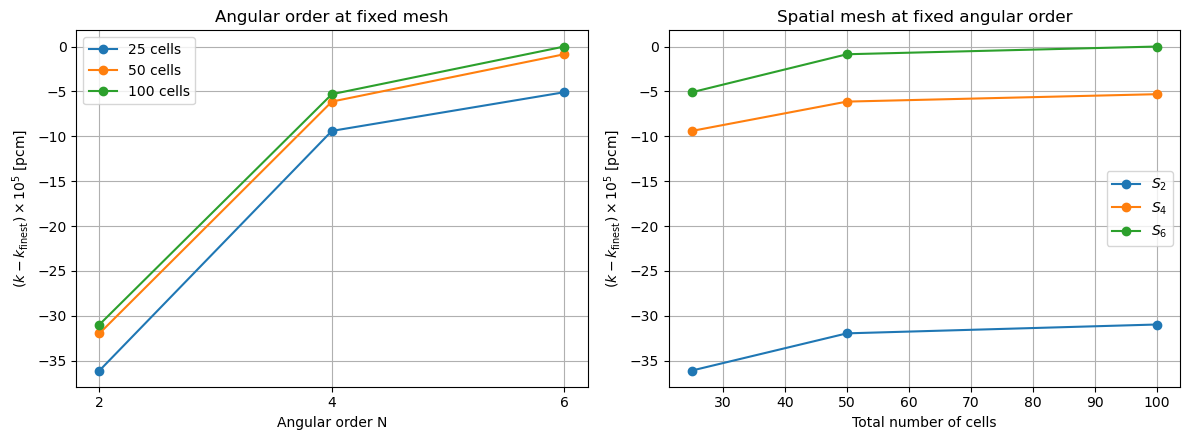

In [8]:
RUN_CONVERGENCE_STUDY = True

if RUN_CONVERGENCE_STUDY:
    # Extend these lists for a more detailed (and more expensive) study.
    ORDERS = (2, 4, 6)                    # Even angular orders
    TARGET_MESH_WIDTHS = (4.0, 2.0, 1.0)  # Target cell widths in cm

    keff_values, spatial_cells = keff_parameter_study(
        solver.problem, ORDERS, TARGET_MESH_WIDTHS,
        use_previous_flux=USE_PREVIOUS_FLUX_AS_INNER_GUESS,
    )

    reference = keff_values[np.argmin(TARGET_MESH_WIDTHS), np.argmax(ORDERS)]
    delta_pcm = (keff_values - reference) * 1e5
    print(f'Finest reference k_eff = {reference:.8f}')
    print('Rows: spatial mesh; columns: angular order N; values: delta k [pcm]')
    print('N =', ORDERS)
    for index, (width, cells) in enumerate(zip(TARGET_MESH_WIDTHS, spatial_cells)):
        print(f'{cells:3d} cells (target dz~{width:g} cm):',
              ' '.join(f'{value:+.1f}' for value in delta_pcm[index]))

    fig, (ax_order, ax_mesh) = plt.subplots(1, 2, figsize=(12, 4.5))
    for row, cells in enumerate(spatial_cells):
        ax_order.plot(ORDERS, delta_pcm[row], 'o-', label=f'{cells} cells')
    ax_order.set(xlabel='Angular order N', ylabel=r'$(k-k_{\mathrm{finest}})\times10^5$ [pcm]',
                 title='Angular order at fixed mesh', xticks=ORDERS)
    ax_order.legend()

    for col, order in enumerate(ORDERS):
        ax_mesh.plot(spatial_cells, delta_pcm[:, col], 'o-', label=fr'$S_{order}$')
    ax_mesh.set(xlabel='Total number of cells', ylabel=r'$(k-k_{\mathrm{finest}})\times10^5$ [pcm]',
                title='Spatial mesh at fixed angular order')
    ax_mesh.legend()
    fig.tight_layout();
else:
    print('Convergence study skipped; set RUN_CONVERGENCE_STUDY = True to run it.')
